# OCT Task 2 — Proposed Hybrid MobileNetV2 + CBAM + GCN

**Architecture:** MobileNetV2 feature extractor → CBAM channel and spatial attention → 7×7 feature grid (49 nodes per image) → two graph-convolution layers → global mean + max pooling → four-class classifier.

**Backbone selection:** MobileNetV2 was selected because it achieved the strongest baseline results in the accompanying baseline evaluation (highest accuracy and macro-F1). This makes the hybrid comparison more informative: MobileNetV2 is compared with the same backbone plus CBAM and GCN.

**Data integrity:** This notebook loads the exact `patient_grouped_manifest.csv` and `cnn_baseline_results.csv` generated by the baseline notebook. It does not rescan images or create a new split. 

**Evaluation:** The hybrid uses exactly the same train, validation, and test image assignments as all four CNN baselines. The test set is used only for final evaluation; validation macro-F1 controls early stopping.


In [1]:
# Imports and configuration
import os, re, time, json, hashlib, random, zipfile
from pathlib import Path
from tqdm.auto import tqdm
from io import BytesIO
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
    precision_recall_curve, average_precision_score, roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt

SEED = 42
CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2
BASELINE_EPOCHS = 5
HYBRID_EPOCHS = 8
PATIENCE = 2
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
USE_PRETRAINED = True
OUTPUT_DIR = Path("/kaggle/working/oct_task2_final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)
if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))

# Locate the folder containing train/, val/, and test/.
KNOWN_ROOTS = [
    Path("/kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017"),
    Path("/kaggle/input/datasets/paultimothymooney/kermany2018/oct2017/OCT2017"),
    Path("/kaggle/input/OCT2017"),
]
def valid_root(p):
    return p.is_dir() and all((p / s).is_dir() for s in ("train", "val", "test"))

DATA_DIR = next((p for p in KNOWN_ROOTS if valid_root(p)), None)
if DATA_DIR is None:
    for root, dirs, files in os.walk("/kaggle/input"):
        candidate = Path(root)
        if valid_root(candidate):
            DATA_DIR = candidate
            break
        depth = len(candidate.parts) - len(Path("/kaggle/input").parts)
        if depth >= 10:
            dirs[:] = []

if DATA_DIR is None:
    raise FileNotFoundError(
        "OCT2017 root not found. Set DATA_DIR to the folder containing train/, val/, and test/."
    )
print("Dataset:", DATA_DIR)

Device: cuda
GPU: Tesla T4
Dataset: /kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 


In [2]:

# LOAD THE EXACT BASELINE MANIFEST AND RESULTS

from io import BytesIO
import zipfile

INPUT_ROOT = Path("/kaggle/input")
BASELINE_ZIP_NAME = "oct_task2_final.zip"

zip_matches = list(INPUT_ROOT.rglob(BASELINE_ZIP_NAME))

def read_artifact_from_zip(zip_path, filename):
    """Read one uniquely named artifact from the baseline output ZIP."""
    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [
            name for name in zf.namelist()
            if Path(name).name == filename
        ]
        if len(members) != 1:
            raise RuntimeError(
                f"Expected exactly one {filename} in {zip_path}; "
                f"found {len(members)}."
            )
        return zf.read(members[0])

if len(zip_matches) == 1:
    baseline_zip = zip_matches[0]
    print("Loading baseline artifacts from:", baseline_zip)

    manifest_bytes = read_artifact_from_zip(
        baseline_zip, "patient_grouped_manifest.csv"
    )
    baseline_bytes = read_artifact_from_zip(
        baseline_zip, "cnn_baseline_results.csv"
    )

    manifest = pd.read_csv(BytesIO(manifest_bytes))
    baseline_df = pd.read_csv(BytesIO(baseline_bytes))

elif len(zip_matches) > 1:
    raise RuntimeError(
        "More than one oct_task2_final.zip was found under /kaggle/input. "
        "Keep only the intended baseline output ZIP attached, or rename/remove "
        "the other attached copy."
    )

else:
    # Alternative: Kaggle may expose output files directly instead of a ZIP.
    manifest_matches = list(INPUT_ROOT.rglob("patient_grouped_manifest.csv"))
    result_matches = list(INPUT_ROOT.rglob("cnn_baseline_results.csv"))

    if len(manifest_matches) != 1 or len(result_matches) != 1:
        raise FileNotFoundError(
            "Could not locate one matching baseline manifest and results CSV. "
            "Attach the baseline notebook output containing "
            "'patient_grouped_manifest.csv' and 'cnn_baseline_results.csv', "
            "preferably as oct_task2_final.zip."
        )

    print("Loading baseline manifest:", manifest_matches[0])
    print("Loading baseline results:", result_matches[0])

    manifest = pd.read_csv(manifest_matches[0])
    baseline_df = pd.read_csv(result_matches[0])


# Validate manifest schema and class mapping


required_columns = {
    "path", "filename", "original_split", "label", "label_id",
    "patient_id", "image_number", "sha256", "group_id", "split"
}

missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(
        f"Baseline manifest is missing required columns: {missing_columns}"
    )

if manifest.empty:
    raise RuntimeError("The baseline manifest is empty.")

if set(manifest["label"].unique()) != set(CLASSES):
    raise RuntimeError(
        "Manifest classes do not match the expected four OCT classes."
    )

for class_name, class_id in CLASS_TO_ID.items():
    observed = set(
        manifest.loc[manifest["label"] == class_name, "label_id"].astype(int)
    )
    if observed != {class_id}:
        raise RuntimeError(
            f"Incorrect label_id mapping for {class_name}: {observed}"
        )

expected_splits = {"train", "val", "test"}
if set(manifest["split"].unique()) != expected_splits:
    raise RuntimeError(
        f"Expected splits {expected_splits}, found {set(manifest['split'].unique())}"
    )

# Verify no patient/source group or exact image crosses splits


group_sets = {
    split: set(manifest.loc[manifest["split"] == split, "group_id"])
    for split in ("train", "val", "test")
}

hash_sets = {
    split: set(manifest.loc[manifest["split"] == split, "sha256"])
    for split in ("train", "val", "test")
}

assert group_sets["train"].isdisjoint(group_sets["val"])
assert group_sets["train"].isdisjoint(group_sets["test"])
assert group_sets["val"].isdisjoint(group_sets["test"])

assert hash_sets["train"].isdisjoint(hash_sets["val"])
assert hash_sets["train"].isdisjoint(hash_sets["test"])
assert hash_sets["val"].isdisjoint(hash_sets["test"])
assert manifest["sha256"].is_unique

# Confirm all classes occur in every partition.
for split_name in ("train", "val", "test"):
    present = set(
        manifest.loc[manifest["split"] == split_name, "label"]
    )
    if present != set(CLASSES):
        raise RuntimeError(
            f"{split_name} is missing classes: {set(CLASSES) - present}"
        )


# Confirm the original OCT2017 image paths are available


print("\nChecking original OCT image paths...")
missing_paths = [
    path for path in tqdm(manifest["path"].tolist(), desc="Checking image files")
    if not Path(path).is_file()
]

if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} manifest image paths are unavailable. "
        "Attach the same original OCT2017 dataset used by the baseline notebook. "
        f"Examples: {missing_paths[:5]}"
    )

# Recreate the exact DataFrames used by the baseline notebook.
train_df = manifest.loc[manifest["split"] == "train"].copy().reset_index(drop=True)
val_df = manifest.loc[manifest["split"] == "val"].copy().reset_index(drop=True)
test_df = manifest.loc[manifest["split"] == "test"].copy().reset_index(drop=True)

# Confirm the four baseline architectures are present in the results.
required_baselines = {
    "MobileNetV2", "ResNet50", "DenseNet121", "EfficientNet-B0"
}
if "model" not in baseline_df.columns:
    raise ValueError("cnn_baseline_results.csv has no 'model' column.")

found_baselines = set(baseline_df["model"])
if not required_baselines.issubset(found_baselines):
    raise RuntimeError(
        f"Baseline results are incomplete. Missing: "
        f"{required_baselines - found_baselines}"
    )

print("\nBASELINE SPLIT LOADED SUCCESSFULLY")
print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Patient/source groups:", manifest["group_id"].nunique())
print("Exact duplicate hashes across splits: ZERO")
print("Patient/source overlap across splits: ZERO")
print("\nBaseline models available:", sorted(required_baselines))
display(
    manifest.groupby("split").agg(
        images=("path", "count"),
        patient_groups=("group_id", "nunique")
    ).reindex(["train", "val", "test"])
)


Loading baseline manifest: /kaggle/input/datasets/scriptsentry/oct-task2-final-zip/patient_grouped_manifest.csv
Loading baseline results: /kaggle/input/datasets/scriptsentry/oct-task2-final-zip/cnn_baseline_results.csv

Checking original OCT image paths...


Checking image files:   0%|          | 0/76677 [00:00<?, ?it/s]


BASELINE SPLIT LOADED SUCCESSFULLY
Train images: 61390
Validation images: 7378
Test images: 7909
Patient/source groups: 4656
Exact duplicate hashes across splits: ZERO
Patient/source overlap across splits: ZERO

Baseline models available: ['DenseNet121', 'EfficientNet-B0', 'MobileNetV2', 'ResNet50']


,images,patient_groups
split,,
train,61390,3733
val,7378,459
test,7909,464


## 3. Preprocessing and dataloaders

In [3]:
# Image transforms and loaders
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(7),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class OCTDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as image:
            image = image.convert("RGB")
        return self.transform(image), int(row.label_id)

train_ds = OCTDataset(train_df, train_transform)
val_ds = OCTDataset(val_df, eval_transform)
test_ds = OCTDataset(test_df, eval_transform)

loader_args = dict(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)
train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df.label_id.to_numpy()
)
CLASS_WEIGHTS = torch.tensor(weights_np, dtype=torch.float32, device=DEVICE)
CRITERION = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
print("Class weights:", dict(zip(CLASSES, weights_np.round(3))))
print("Images:", len(train_ds), "train |", len(val_ds), "validation |", len(test_ds), "test")

Class weights: {'CNV': np.float64(0.614), 'DME': np.float64(1.684), 'DRUSEN': np.float64(2.452), 'NORMAL': np.float64(0.73)}
Images: 61390 train | 7378 validation | 7909 test


training n evaluation utilities

In [4]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

@torch.no_grad()
def predict(model, loader):
    model.eval()
    y_true, y_prob = [], []
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        logits = model(images)
        y_prob.extend(torch.softmax(logits.float(), dim=1).cpu().numpy())
        y_true.extend(labels.numpy())
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    # Includes data loading, host-to-device transfer, and model execution
    # (end-to-end test pipeline latency, not isolated GPU kernel latency).
    return np.asarray(y_true), np.asarray(y_prob), elapsed

def evaluate_model(model, model_name):
    y_true, y_prob, inference_seconds = predict(model, test_loader)
    y_pred = y_prob.argmax(axis=1)
    report = classification_report(
        y_true, y_pred, labels=np.arange(len(CLASSES)),
        target_names=CLASSES, output_dict=True, zero_division=0
    )
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    y_bin = np.eye(len(CLASSES))[y_true]

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASSES)))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name}_confusion_matrix.png", dpi=160)
    plt.show()
    print("Reading: Diagonal cells are correct predictions; off-diagonal cells show which classes are confused.")

    # One-vs-rest ROC
    per_class_auc, per_class_ap = {}, {}
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, name in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        per_class_auc[name] = roc_auc_score(y_bin[:, i], y_prob[:, i])
        ax.plot(fpr, tpr, label=f"{name} (AUC={per_class_auc[name]:.3f})")
    ax.plot([0, 1], [0, 1], "--", label="Chance")
    ax.set_title(f"{model_name} — One-vs-Rest ROC Curves")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name}_roc_ovr.png", dpi=160)
    plt.show()
    print("Reading: A curve closer to the upper-left and a larger AUC indicate better class discrimination.")

    # One-vs-rest precision-recall
    fig, ax = plt.subplots(figsize=(8, 6))
    supports = []
    for i, name in enumerate(CLASSES):
        precision, recall, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i])
        per_class_ap[name] = average_precision_score(y_bin[:, i], y_prob[:, i])
        supports.append(int(y_bin[:, i].sum()))
        ax.plot(recall, precision, label=f"{name} (AP={per_class_ap[name]:.3f})")
    ax.set_title(f"{model_name} — One-vs-Rest Precision–Recall Curves")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name}_pr_ovr.png", dpi=160)
    plt.show()
    print("Reading: Higher precision at the same recall is better; AP summarizes each class curve.")
    print("Timing note: milliseconds/image includes test data loading, transfer, and model execution.")

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p_macro, "macro_recall": r_macro, "macro_f1": f_macro,
        "weighted_precision": p_weighted, "weighted_recall": r_weighted,
        "weighted_f1": f_weighted,
        "macro_roc_auc_ovr": roc_auc_score(y_true, y_prob, average="macro", multi_class="ovr"),
        "weighted_roc_auc_ovr": roc_auc_score(y_true, y_prob, average="weighted", multi_class="ovr"),
        "macro_average_precision_ovr": float(np.mean(list(per_class_ap.values()))),
        "weighted_average_precision_ovr": float(np.average(list(per_class_ap.values()), weights=supports)),
        "inference_ms_per_image": inference_seconds * 1000 / len(test_ds)
    }
    for name in CLASSES:
        result[f"{name}_precision"] = report[name]["precision"]
        result[f"{name}_recall"] = report[name]["recall"]
        result[f"{name}_f1"] = report[name]["f1-score"]
        result[f"{name}_roc_auc"] = per_class_auc[name]
        result[f"{name}_average_precision"] = per_class_ap[name]

    pd.DataFrame(report).T.to_csv(OUTPUT_DIR / f"{model_name}_classification_report.csv")
    return result, cm

def train_model(model, model_name, epochs):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best_f1, stale = -1.0, 0
    checkpoint = OUTPUT_DIR / f"{model_name}_best.pt"
    history = []
    start_all = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        # Frozen CNN blocks must also keep BatchNorm in evaluation mode;
        # requires_grad=False alone does not freeze BatchNorm running statistics.
        if hasattr(model, "cnn"):
            for block in model.cnn:
                if not any(parameter.requires_grad for parameter in block.parameters()):
                    block.eval()
        loss_sum, seen = 0.0, 0
        start_epoch = time.perf_counter()
        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(images)
                loss = CRITERION(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            loss_sum += loss.item() * labels.size(0)
            seen += labels.size(0)

        val_true, val_prob, _ = predict(model, val_loader)
        val_f1 = precision_recall_fscore_support(
            val_true, val_prob.argmax(1), average="macro", zero_division=0
        )[2]
        history.append({
            "epoch": epoch, "train_loss": loss_sum / seen,
            "validation_macro_f1": val_f1
        })
        print(
            f"{model_name} | epoch {epoch}/{epochs} | "
            f"loss={loss_sum/seen:.4f} | val_macro_F1={val_f1:.4f} | "
            f"minutes={(time.perf_counter()-start_epoch)/60:.1f}"
        )
        if val_f1 > best_f1:
            best_f1, stale = val_f1, 0
            torch.save(model.state_dict(), checkpoint)
        else:
            stale += 1
            if stale >= PATIENCE:
                print("Early stopping.")
                break

    training_seconds = time.perf_counter() - start_all
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    pd.DataFrame(history).to_csv(OUTPUT_DIR / f"{model_name}_history.csv", index=False)
    return model, training_seconds, checkpoint

In [5]:

# hybrid arch: mobinet_v2 + cabam + gcn


# CBAM: channel attention followed by spatial attention.
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 1)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )

    def forward(self, x):
        attention = (
            self.mlp(F.adaptive_avg_pool2d(x, 1))
            + self.mlp(F.adaptive_max_pool2d(x, 1))
        )
        return torch.sigmoid(attention)


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(
            2, 1, kernel_size=7, padding=3, bias=False
        )

    def forward(self, x):
        avg = x.mean(dim=1, keepdim=True)
        maximum = x.max(dim=1, keepdim=True).values
        return torch.sigmoid(
            self.conv(torch.cat([avg, maximum], dim=1))
        )


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel = ChannelAttention(channels)
        self.spatial = SpatialAttention()

    def forward(self, x):
        x = x * self.channel(x)
        x = x * self.spatial(x)
        return x


# 7x7 spatial grid
# 49 nodes n 8neighbour connections n self-loops.
def normalized_grid_adjacency(size=7):
    n = size * size
    adjacency = torch.zeros(n, n)

    for row in range(size):
        for col in range(size):
            node = row * size + col
            adjacency[node, node] = 1.0

            for dr in (-1, 0, 1):
                for dc in (-1, 0, 1):
                    if dr == 0 and dc == 0:
                        continue

                    rr, cc = row + dr, col + dc

                    if 0 <= rr < size and 0 <= cc < size:
                        neighbour = rr * size + cc
                        adjacency[node, neighbour] = 1.0

    degree = adjacency.sum(dim=1).clamp_min(1.0)
    degree_inv_sqrt = degree.rsqrt()

    # Symmetric degree normalization: D^(-1/2) A D^(-1/2)
    return (
        degree_inv_sqrt[:, None]
        * adjacency
        * degree_inv_sqrt[None, :]
    )


class GraphConv(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, node_features, adjacency):
        transformed = self.linear(node_features)
        return torch.matmul(adjacency.unsqueeze(0), transformed)


class OCT_CNN_CBAM_GCN(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        # mobi was betterr=
        weights = (
            models.MobileNet_V2_Weights.DEFAULT
            if pretrained else None
        )
        backbone = models.mobilenet_v2(weights=weights)

        self.cnn = backbone.features
        channels = backbone.last_channel  # 1280

        # Keep the complete backbone trainable, matching the baseline
        # fine-tuning strategy for a fairer backbone comparison.
        for parameter in self.cnn.parameters():
            parameter.requires_grad = True

        self.attention = CBAM(channels)

        self.gcn1 = GraphConv(channels, 256)
        self.gcn2 = GraphConv(256, 128)

        self.dropout = nn.Dropout(0.30)

        # Mean pooling (128) + max pooling (128) = 256 features.
        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(128, len(CLASSES))
        )

        self.register_buffer(
            "adjacency",
            normalized_grid_adjacency(size=7)
        )

    def forward(self, images):

        # CNN feature extraction.
        feature_map = self.cnn(images)

        # Channel and spatial attention.
        feature_map = self.attention(feature_map)

        # Fixed 7x7 grid: 49 nodes per image.
        feature_map = F.adaptive_avg_pool2d(
            feature_map, output_size=(7, 7)
        )

        # [B, 1280, 7, 7] -> [B, 49, 1280]
        nodes = feature_map.flatten(2).transpose(1, 2)

        # Two graph-convolution layers.
        nodes = self.dropout(
            F.relu(self.gcn1(nodes, self.adjacency))
        )

        nodes = F.relu(
            self.gcn2(nodes, self.adjacency)
        )

        # Global mean + max readout.
        graph_features = torch.cat(
            [
                nodes.mean(dim=1),
                nodes.max(dim=1).values
            ],
            dim=1
        )

        return self.classifier(graph_features)


hybrid = OCT_CNN_CBAM_GCN(pretrained=USE_PRETRAINED)

total_params, trainable_params = count_parameters(hybrid)

print(hybrid)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print(
    "All CNN backbone parameters trainable:",
    all(p.requires_grad for p in hybrid.cnn.parameters())
)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 110MB/s] 


OCT_CNN_CBAM_GCN(
  (cnn): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

## 6. Train and evaluate the hybrid

/tmp/ipykernel_126/3914061142.py:119: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_126/3914061142.py:139: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2_CBAM_GCN | epoch 1/8 | loss=0.3453 | val_macro_F1=0.9360 | minutes=46.5


/tmp/ipykernel_126/3914061142.py:139: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2_CBAM_GCN | epoch 2/8 | loss=0.1922 | val_macro_F1=0.9309 | minutes=4.9


/tmp/ipykernel_126/3914061142.py:139: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2_CBAM_GCN | epoch 3/8 | loss=0.1620 | val_macro_F1=0.9414 | minutes=4.9


... (6 outputs left out)

/tmp/ipykernel_126/3914061142.py:139: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2_CBAM_GCN | epoch 7/8 | loss=0.1063 | val_macro_F1=0.9457 | minutes=5.0


/tmp/ipykernel_126/3914061142.py:139: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


MobileNetV2_CBAM_GCN | epoch 8/8 | loss=0.0956 | val_macro_F1=0.9299 | minutes=5.0


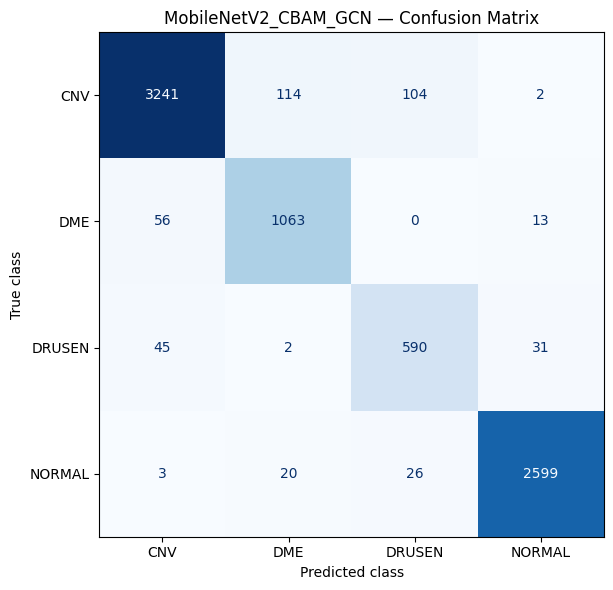

Reading: Diagonal cells are correct predictions; off-diagonal cells show which classes are confused.


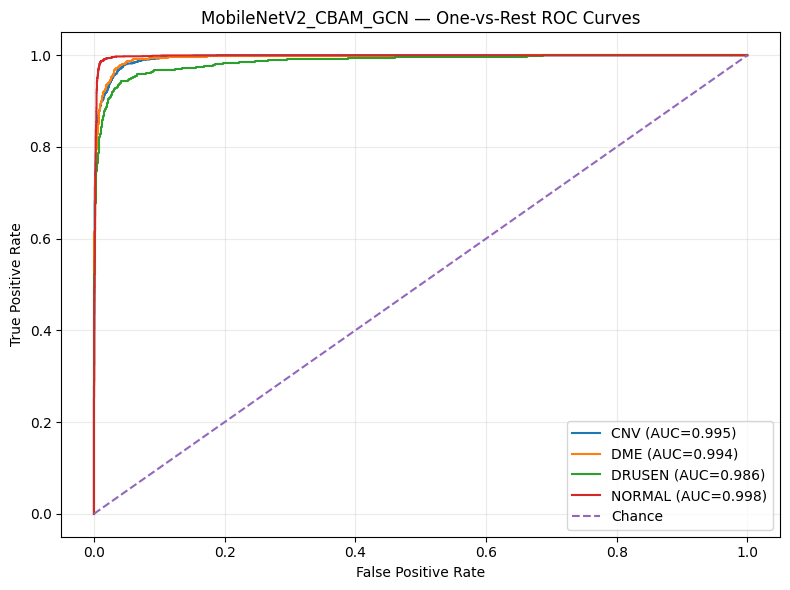

Reading: A curve closer to the upper-left and a larger AUC indicate better class discrimination.


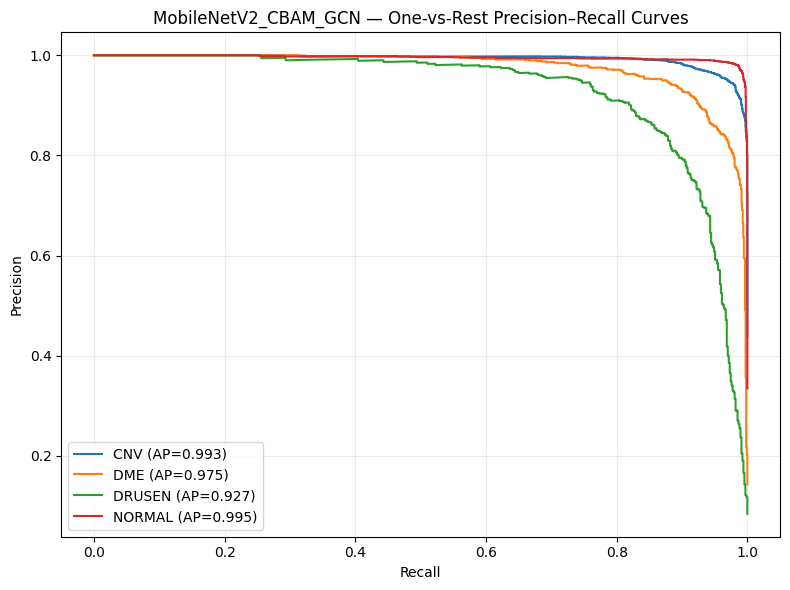

Reading: Higher precision at the same recall is better; AP summarizes each class curve.
Timing note: milliseconds/image includes test data loading, transfer, and model execution.

FINAL FIVE-MODEL COMPARISON


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_roc_auc_ovr,macro_average_precision_ovr,training_minutes,inference_ms_per_image,total_parameters,model_size_mb
0,MobileNetV2,0.955494,0.925765,0.945747,0.935237,0.955936,0.994807,0.975943,24.486952,3.968315,2228996,8.739024
1,DenseNet121,0.953218,0.917286,0.952179,0.932993,0.954145,0.995782,0.975478,36.820531,4.162296,6957956,27.125753
2,MobileNetV2_CBAM_GCN,0.947402,0.914384,0.935052,0.924161,0.947914,0.993278,0.972607,81.160952,39.772837,2823014,11.018229
3,ResNet50,0.946643,0.905506,0.946207,0.923359,0.947841,0.992955,0.961465,26.573275,4.149732,23516228,90.012424
4,EfficientNet-B0,0.946643,0.906918,0.943418,0.922355,0.948065,0.992763,0.960443,25.456609,3.889021,4012672,15.596257



Hybrid checkpoint: /kaggle/working/oct_task2_final/MobileNetV2_CBAM_GCN_best.pt
Comparison CSV: /kaggle/working/oct_task2_final/all_five_models_comparison.csv
Outputs: /kaggle/working/oct_task2_final


In [6]:

# train n evaluate hybrid mobel

hybrid, train_seconds, checkpoint = train_model(
    hybrid,
    "MobileNetV2_CBAM_GCN",
    HYBRID_EPOCHS
)

# Final evaluation is performed on the exact same held-out test set
# used for all four CNN baselines.
hybrid_result, hybrid_cm = evaluate_model(
    hybrid,
    "MobileNetV2_CBAM_GCN"
)

hybrid_result.update({
    "training_minutes": train_seconds / 60,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "model_size_mb": checkpoint.stat().st_size / (1024 ** 2)
})

hybrid_df = pd.DataFrame([hybrid_result])

hybrid_df.to_csv(
    OUTPUT_DIR / "hybrid_results.csv",
    index=False
)

# Combine four baseline models with the proposed hybrid.
all_results = pd.concat(
    [baseline_df, hybrid_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

all_results.to_csv(
    OUTPUT_DIR / "all_five_models_comparison.csv",
    index=False
)

print("\nFINAL FIVE-MODEL COMPARISON")
display(
    all_results[
        [
            "model",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",
            "macro_roc_auc_ovr",
            "macro_average_precision_ovr",
            "training_minutes",
            "inference_ms_per_image",
            "total_parameters",
            "model_size_mb"
        ]
    ]
)

print("\nHybrid checkpoint:", checkpoint)
print("Comparison CSV:", OUTPUT_DIR / "all_five_models_comparison.csv")
print("Outputs:", OUTPUT_DIR)


## 7. Architecture Explanation

The proposed hybrid model combines MobileNetV2, CBAM, and GCN for OCT image classification.

- **CNN Backbone:** MobileNetV2 extracts image features. It was selected because it achieved the best baseline accuracy (95.55%) and macro-F1 (93.52%).
- **CBAM Attention:** Channel attention highlights important feature channels, while spatial attention focuses on informative image regions.
- **Graph Nodes:** The feature map is pooled to 7 × 7, producing 49 nodes per image, each containing 1,280 features.
- **Graph Edges:** Each node connects to its eight neighbouring nodes and itself. A symmetric, degree-normalized adjacency matrix is used.
- **GCN:** Two graph-convolution layers transform features from 1,280 → 256 → 128, using ReLU and dropout.
- **Classification:** Global mean and max pooling are combined and passed through a 256 → 128 → 4 classifier.
- **Training:** The entire MobileNetV2 backbone, CBAM, GCN, and classifier are trainable.

### Graph Construction Justification

A 7 × 7 feature grid is used instead of raw-image superpixels to keep graph construction computationally efficient. Each node represents a spatial feature-map location, while edges connect nearby regions. The fixed graph allows the GCN to learn relationships between neighbouring image features.

### Performance and Limitations

The hybrid model achieved 94.74% accuracy and 92.42% macro-F1, compared with 95.55% accuracy and 93.52% macro-F1 for the MobileNetV2 baseline. It also required more training time (81.16 vs. 24.49 minutes) and inference time (39.77 vs. 3.97 ms/image).

Although the hybrid achieved competitive results, it did not outperform the best CNN baseline. The fixed graph represents spatial relationships rather than actual retinal anatomy, and attention weights alone do not provide clinical explanations.

In [7]:

import shutil
from pathlib import Path
from IPython.display import FileLink, display

# Source folder
folder = Path("/kaggle/working/oct_task2_final")

# ZIP destination
zip_path = Path("/kaggle/working/oct_task2_final.zip")

# Verify folder
if not folder.exists():
    raise FileNotFoundError(f"Folder not found: {folder}")

# Compress folder
shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=folder.parent,
    base_dir=folder.name
)

print("ZIP created successfully!")
print(f"File size: {zip_path.stat().st_size / (1024**2):.2f} MB")

# Display clickable download link
display(FileLink(str(zip_path)))


ZIP created successfully!
File size: 10.32 MB


/kaggle/working/oct_task2_final.zip